# Лабораторна робота №4
**Тема:** Дослідження дерев рішень та ансамблевих методів у задачі багатокласової класифікації за наявності пропущених значень

**Виконала:** Цюрпіта Діана, ФЕІ-44

**Мета:** порівняти Decision Tree, Random Forest і XGBoost на Annealing; перевірити вплив індикаторів пропусків, підібрати гіперпараметри Optuna, провести вкладену CV, статистичне порівняння та інтерпретацію SHAP.

**Важливо:** за методичкою `SEED = 42 + N`, де `N` — номер у списку групи. Перед запуском впишіть свій номер у першій клітинці. Числові таблиці та висновки генеруються **за реальними результатами запуску**, а не наперед.

In [1]:
N = 11  # Мій номер у списку групи
SEED = 42 + N
N_TRIALS = 30  # кількість спроб Optuna згідно з методичкою; повний запуск тривалий
print(f"Номер у списку: {N}; SEED={SEED}; Optuna trials={N_TRIALS}")

Номер у списку: 11; SEED=53; Optuna trials=30


## 0. Середовище та версії бібліотек
Бібліотеки встановлюються автоматично за потреби. Датасет завантажується **локально** з `anneal.data` та `anneal.test` у тій самій папці, що й Notebook; OpenML не потрібний.

In [2]:
# Автоматична перевірка та встановлення бібліотек для лабораторної №4
# Запустіть цю клітинку перед імпортами. Потрібен доступ до інтернету.
import sys, subprocess, importlib.util
packages = {
    "numpy": "numpy>=1.26", "pandas": "pandas>=2.0",
    "matplotlib": "matplotlib>=3.8", "sklearn": "scikit-learn>=1.4",
    "xgboost": "xgboost>=2.0", "optuna": "optuna>=3.0",
    "shap": "shap>=0.44", "scipy": "scipy>=1.11", "joblib": "joblib>=1.3"
}
missing = [spec for module, spec in packages.items() if importlib.util.find_spec(module) is None]
if missing:
    print("Встановлюємо відсутні бібліотеки:", ", ".join(missing))
    subprocess.check_call([sys.executable, "-m", "pip", "install", *missing])
    importlib.invalidate_caches()
    print("Встановлення завершено. Якщо імпорт не спрацює, перезапустіть Kernel і виконайте Run All.")
else:
    print("Усі необхідні бібліотеки вже встановлені.")

Усі необхідні бібліотеки вже встановлені.


In [3]:
import sys, warnings, importlib.metadata as metadata
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import sklearn, xgboost, optuna, shap, scipy
from IPython.display import display, Markdown
from sklearn.datasets import fetch_openml
from sklearn.model_selection import train_test_split, RepeatedStratifiedKFold, StratifiedKFold, cross_validate, cross_val_score, cross_val_predict
from sklearn.preprocessing import OneHotEncoder, LabelEncoder
from sklearn.impute import SimpleImputer, MissingIndicator
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from sklearn.metrics import accuracy_score, f1_score, balanced_accuracy_score, classification_report, ConfusionMatrixDisplay
from sklearn.inspection import permutation_importance
from scipy.stats import chi2_contingency, t as student_t
from pathlib import Path
import joblib
warnings.filterwarnings("ignore", category=FutureWarning)
optuna.logging.set_verbosity(optuna.logging.WARNING)
versions = {p:metadata.version(p) for p in ['numpy','pandas','scikit-learn','xgboost','optuna','shap','scipy','matplotlib']}
display(pd.Series(versions, name='Версія').to_frame())
Path('models_lab4').mkdir(exist_ok=True)

,Версія
numpy,2.1.1
pandas,2.2.3
scikit-learn,1.6.1
xgboost,3.4.1
optuna,5.0.0
shap,0.54.1
scipy,1.14.1
matplotlib,3.10.1


## 1. Первинний аналіз Annealing
Джерело: UCI Machine Learning Repository, оригінальні файли `anneal.data` (798 рядків) та `anneal.test` (100 рядків). Вони об'єднуються в 898 спостережень і далі розбиваються стратифіковано за методикою. `?` означає пропуск, а `-` — окрема допустима категорія «не застосовується» (не пропуск).

**Контроль витоку:** перед поділом даних видаляємо однакові рядки за інформативними ознаками. Оскільки дублікати могли б потрапити в Train і Test одночасно, без цього незалежність оцінки сумнівна. Перевіряємо також, що однакові ознаки не мають суперечливих класів.

Джерело UCI; спостережень: 898 ; початкових ознак: 38
Типи: {'object': 32, 'int64': 4, 'float64': 2}
Вилучені повністю порожні/константні ознаки: ['bc', 'bf', 'bl', 'bt', 'cbond', 'chrom', 'corr', 'exptl', 'ferro', 'jurofm', 'lustre', 'm', 'marvi', 'non-ageing', 'p', 'phos', 'product-type', 's', 'surface-finish', 'temper_rolling']
Виявлено і вилучено дублікатів після очищення ознак: 105


,Частка пропусків
blue/bright/varn/clean,0.992434
packing,0.988651
enamelability,0.979823
oil,0.938209
family,0.853720
bw/me,0.759142
formability,0.363178
condition,0.348045
surface-quality,0.272383
steel,0.102144


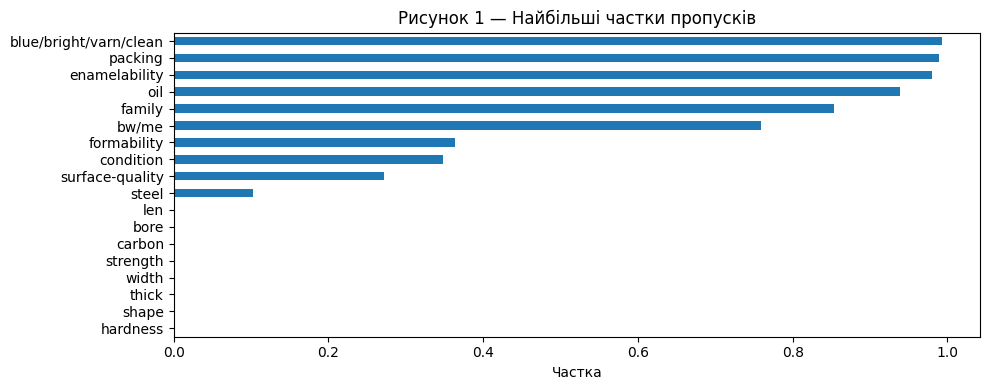

,Кількість
class,
3,605
2,84
5,59
U,37
1,8


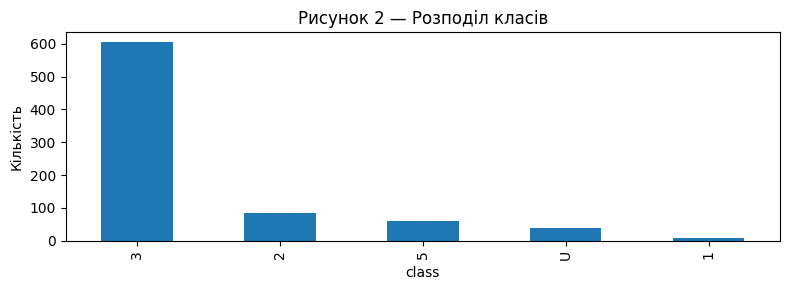

In [4]:
# Локальне завантаження UCI Annealing без звернення до OpenML
from pathlib import Path
import re
names_text = Path('anneal.names').read_text(encoding='utf-8', errors='replace')
attribute_block = names_text.split('7. Attribute Information:', 1)[1].split('classes:', 1)[0]
names = re.findall(r'^\s*\d+\.\s+([^:\n]+):', attribute_block, flags=re.MULTILINE)
assert len(names) == 38, f'Очікувалось 38 назв ознак, отримано {len(names)}'
columns = names + ['class']
train_raw = pd.read_csv('anneal.data', header=None, names=columns, dtype=str, na_values=['?'], keep_default_na=False)
test_raw = pd.read_csv('anneal.test', header=None, names=columns, dtype=str, na_values=['?'], keep_default_na=False)
assert train_raw.shape == (798, 39) and test_raw.shape == (100, 39), (train_raw.shape, test_raw.shape)
combined = pd.concat([train_raw, test_raw], ignore_index=True)
X = combined.drop(columns='class').copy()
y = combined['class'].astype(str).copy()
numeric_columns = ['carbon', 'hardness', 'strength', 'thick', 'width', 'len']
for c in numeric_columns:
    X[c] = pd.to_numeric(X[c], errors='coerce')
for c in X.columns.difference(numeric_columns):
    X[c] = X[c].astype('object')

print('Джерело UCI; спостережень:', len(X), '; початкових ознак:', X.shape[1])
print('Типи:', X.dtypes.astype(str).value_counts().to_dict())
empty = X.columns[X.isna().all()].tolist()
constant = [c for c in X if X[c].dropna().nunique() <= 1]
removed = sorted(set(empty + constant))
print('Вилучені повністю порожні/константні ознаки:', removed)
X = X.drop(columns=removed)
# Усунення витоку: після вилучення неінформативних ознак
# однакові об'єкти можуть опинитися одночасно у Train і Test.
# Перевіряємо, що однакові ознаки не мають суперечливих міток.
feature_key = X.fillna('<MISSING_VALUE>').astype(str).agg('\x1f'.join, axis=1)
conflicts = pd.DataFrame({'key': feature_key, 'target': y}).groupby('key')['target'].nunique()
assert not (conflicts > 1).any(), 'Однакові ознаки мають різні класи: потрібен окремий аналіз!'
unique_mask = ~feature_key.duplicated(keep='first')
print('Виявлено і вилучено дублікатів після очищення ознак:', int((~unique_mask).sum()))
X = X.loc[unique_mask].reset_index(drop=True)
y = y.loc[unique_mask].reset_index(drop=True)
missing = X.isna().mean().sort_values(ascending=False)
display(missing.rename('Частка пропусків').to_frame().head(20))
fig,ax=plt.subplots(figsize=(10,4))
missing.head(20).sort_values().plot.barh(ax=ax)
ax.set_title('Рисунок 1 — Найбільші частки пропусків'); ax.set_xlabel('Частка')
plt.tight_layout(); plt.show()
counts=y.value_counts()
display(counts.rename('Кількість').to_frame())
fig,ax=plt.subplots(figsize=(8,3))
counts.plot.bar(ax=ax)
ax.set_title('Рисунок 2 — Розподіл класів'); ax.set_ylabel('Кількість')
plt.tight_layout(); plt.show()

### Рідкісні класи
Після видалення дублікатів класи перераховуються. Для зовнішньої 5-блочної CV і внутрішньої 3-блочної CV найменший клас повинен мати достатньо прикладів. Щоб зберегти коректну багатокласову постановку, класи з менш ніж **10 об'єктами** виключаються **до** розбиття. Це явне методичне рішення: метрики після цього описують лише залишені класи, а не всі початкові класи. Не слід робити висновки про виключені класи.

In [5]:
rare = counts[counts < 10].index.tolist()
print('Виключені надто рідкісні класи:', rare)
keep = ~y.isin(rare)
X = X.loc[keep].reset_index(drop=True)
y = y.loc[keep].reset_index(drop=True)
assert y.nunique() >= 2
enc=LabelEncoder()
y_enc=enc.fit_transform(y)
print('Залишено:',len(X),'спостережень;',len(enc.classes_),'класів')
display(pd.DataFrame({'Клас':enc.classes_, 'Кількість':[sum(y==c) for c in enc.classes_]}))
rows=[]
for c in missing.head(5).index:
    if c not in X.columns: continue
    tab=pd.crosstab(X[c].isna().map({True:'Пропуск',False:'Є значення'}),y)
    if tab.shape[0]<2: continue
    chi2,p,dof,_=chi2_contingency(tab)
    rows.append({'Ознака':c,'p-value χ²':p,'Зв’язок із класом (p<0.05)':p<0.05})
    display(Markdown(f'**Ознака `{c}` — таблиця пропуск × клас**'))
    display(tab)
chi_df=pd.DataFrame(rows)
display(chi_df)
if len(chi_df):
    print('Зв’язок пропусків із класом знайдено у',int(chi_df['Зв’язок із класом (p<0.05)'].sum()),'із',len(chi_df),'перевірених ознак.')
print('Залежність від класу не дозволяє однозначно розрізнити MAR та MNAR; відсутність залежності не доводить MCAR.')

Виключені надто рідкісні класи: ['1']
Залишено: 785 спостережень; 4 класів


,Клас,Кількість
0,2,84
1,3,605
2,5,59
3,U,37


**Ознака `blue/bright/varn/clean` — таблиця пропуск × клас**

class,2,3,5,U
blue/bright/varn/clean,,,,
Є значення,4,1,0,0
Пропуск,80,604,59,37


**Ознака `packing` — таблиця пропуск × клас**

...

class,2,3,5,U
oil,,,,
Є значення,0,42,0,7
Пропуск,84,563,59,30


**Ознака `family` — таблиця пропуск × клас**

class,2,3,5,U
family,,,,
Є значення,0,44,59,11
Пропуск,84,561,0,26


,Ознака,p-value χ²,Зв’язок із класом (p<0.05)
0,blue/bright/varn/clean,1.319996e-05,True
1,packing,4.387438e-01,False
2,enamelability,4.968594e-10,True
3,oil,1.552457e-04,True
4,family,4.301995e-85,True


Зв’язок пропусків із класом знайдено у 4 із 5 перевірених ознак.
Залежність від класу не дозволяє однозначно розрізнити MAR та MNAR; відсутність залежності не доводить MCAR.


## 2. Стратифікований поділ та два пайплайни
Тестові дані використовуються лише після підбору моделей. Усі параметри імпутації визначаються всередині CV. A — медіана/мода + one-hot; B — те саме + індикатори пропусків.

In [6]:
X_train,X_test,y_train,y_test=train_test_split(X,y_enc,test_size=0.2,stratify=y_enc,random_state=SEED)
print('Train:',len(X_train),'Test:',len(X_test))
# Перевірка на збіг однакових об'єктів між навчальною і тестовою вибірками.
def row_keys(frame):
    return set(frame.fillna('<MISSING_VALUE>').astype(str).agg('\x1f'.join,axis=1))
overlap = row_keys(X_train) & row_keys(X_test)
assert not overlap, f'Витік даних: {len(overlap)} однакових записів у Train і Test!'
print('Перевірка дублікатів Train/Test: перетин = 0, витоку через дублікати немає.')
num_cols=X_train.select_dtypes(include='number').columns.tolist()
cat_cols=[c for c in X_train if c not in num_cols]
missing_cols=X_train.columns[X_train.isna().any()].tolist()
print('Числові:',len(num_cols),'категоріальні:',len(cat_cols),'з пропусками:',len(missing_cols))
def build_preprocessor(with_indicators=False):
    parts=[]
    if num_cols:
        parts.append(('num',SimpleImputer(strategy='median', keep_empty_features=True),num_cols))
    if cat_cols:
        parts.append(('cat',Pipeline([
            ('impute',SimpleImputer(strategy='most_frequent', keep_empty_features=True)),
            ('onehot',OneHotEncoder(handle_unknown='ignore',sparse_output=False))
        ]),cat_cols))
    if with_indicators and missing_cols:
        parts.append(('missingindicator',MissingIndicator(features='all'),missing_cols))
    return ColumnTransformer(parts,sparse_threshold=0,verbose_feature_names_out=True)
def make_model(name,params=None):
    p=dict(params or {})
    if name=='DT': return DecisionTreeClassifier(random_state=SEED,**p)
    if name=='RF': return RandomForestClassifier(random_state=SEED,n_jobs=1,**p)
    if name=='XGB': return XGBClassifier(random_state=SEED,n_jobs=1,eval_metric='mlogloss',tree_method='hist',**p)
    raise ValueError(name)
def build_pipeline(name,with_indicators=True,params=None):
    return Pipeline([('prep',build_preprocessor(with_indicators)),('clf',make_model(name,params))])

Train: 628 Test: 157
Перевірка дублікатів Train/Test: перетин = 0, витоку через дублікати немає.
Числові: 6 категоріальні: 12 з пропусками: 10


## 3. Базові моделі — таблиці 1 і 2
Для всіх шести комбінацій використано ті самі 15 блоків (5 × 3). Основна метрика — macro F1. Відображено середнє ± стандартне відхилення.

In [7]:
cv=RepeatedStratifiedKFold(n_splits=5,n_repeats=3,random_state=SEED)
scoring={'accuracy':'accuracy','macro F1':'f1_macro','balanced accuracy':'balanced_accuracy'}
base_scores={}
records=[]
for variant,ind in [('A',False),('B',True)]:
    for name in ['DT','RF','XGB']:
        print('Базова CV:',variant,name,flush=True)
        r=cross_validate(build_pipeline(name,ind),X_train,y_train,cv=cv,scoring=scoring,n_jobs=1,error_score='raise')
        base_scores[(variant,name)]={metric:r['test_'+metric] for metric in scoring}
        records.append({'Варіант':variant,'Модель':name,**{metric:f"{r['test_'+metric].mean():.4f} ± {r['test_'+metric].std(ddof=1):.4f}" for metric in scoring}})
base_table=pd.DataFrame(records)
display(Markdown('**Таблиця 1 — Варіант A**'));display(base_table.query("Варіант=='A'"))
display(Markdown('**Таблиця 2 — Варіант B**'));display(base_table.query("Варіант=='B'"))
for name in ['DT','RF','XGB']:
    a=base_scores[('A',name)]['macro F1'].mean()
    b=base_scores[('B',name)]['macro F1'].mean()
    print(f'{name}: зміна macro F1 після додавання індикаторів: {b-a:+.4f}')

Базова CV: A DT
Базова CV: A RF
Базова CV: A XGB
Базова CV: B DT
Базова CV: B RF
Базова CV: B XGB


**Таблиця 1 — Варіант A**

,Варіант,Модель,accuracy,macro F1,balanced accuracy
0,A,DT,0.9342 ± 0.0251,0.8911 ± 0.0450,0.8935 ± 0.0515
1,A,RF,0.9357 ± 0.0241,0.8991 ± 0.0450,0.9029 ± 0.0523
2,A,XGB,0.9416 ± 0.0228,0.9085 ± 0.0408,0.9054 ± 0.0434


**Таблиця 2 — Варіант B**

,Варіант,Модель,accuracy,macro F1,balanced accuracy
3,B,DT,0.9910 ± 0.0084,0.9734 ± 0.0262,0.9684 ± 0.0396
4,B,RF,0.9942 ± 0.0077,0.9876 ± 0.0173,0.9871 ± 0.0228
5,B,XGB,0.9904 ± 0.0091,0.9804 ± 0.0210,0.9765 ± 0.0318


DT: зміна macro F1 після додавання індикаторів: +0.0824
RF: зміна macro F1 після додавання індикаторів: +0.0885
XGB: зміна macro F1 після додавання індикаторів: +0.0718


## 4. Optuna та вкладена крос-валідація — таблиці 3 і 4
Внутрішня CV (3 блоки) добирає параметри, зовнішня (5 блоків) оцінює процедуру налаштування. `best_value` не вважаємо незалежною оцінкою якості. **Увага:** 3 моделі × (5 зовнішніх + 1 фінальний) × 30 trials × 3 блоки — обчислювально тривалий етап.

In [8]:
def suggest_params(trial,name):
    if name=='DT':
        return {'max_depth':trial.suggest_int('max_depth',2,20),
                'min_samples_split':trial.suggest_int('min_samples_split',2,20),
                'min_samples_leaf':trial.suggest_int('min_samples_leaf',1,10),
                'class_weight':trial.suggest_categorical('class_weight',[None,'balanced'])}
    if name=='RF':
        return {'n_estimators':trial.suggest_int('n_estimators',100,500,step=50),
                'max_depth':trial.suggest_int('max_depth',3,30),
                'min_samples_leaf':trial.suggest_int('min_samples_leaf',1,10),
                'max_features':trial.suggest_categorical('max_features',['sqrt','log2',0.5]),
                'class_weight':trial.suggest_categorical('class_weight',[None,'balanced','balanced_subsample'])}
    return {'n_estimators':trial.suggest_int('n_estimators',50,400),
            'max_depth':trial.suggest_int('max_depth',2,10),
            'learning_rate':trial.suggest_float('learning_rate',0.01,0.3,log=True),
            'subsample':trial.suggest_float('subsample',0.6,1.0),
            'colsample_bytree':trial.suggest_float('colsample_bytree',0.6,1.0),
            'min_child_weight':trial.suggest_float('min_child_weight',1,10,log=True)}
def tune(name,Xtr,ytr,n_trials=N_TRIALS):
    inner=StratifiedKFold(n_splits=3,shuffle=True,random_state=SEED)
    def objective(trial):
        pipe=build_pipeline(name,True,suggest_params(trial,name))
        return cross_val_score(pipe,Xtr,ytr,cv=inner,scoring='f1_macro',n_jobs=1,error_score='raise').mean()
    study=optuna.create_study(direction='maximize',sampler=optuna.samplers.TPESampler(seed=SEED))
    study.optimize(objective,n_trials=n_trials,show_progress_bar=False)
    return study
outer=StratifiedKFold(n_splits=5,shuffle=True,random_state=SEED)
nested={}
studies={}
final_models={}
nested_rows=[]
param_rows=[]
for name in ['DT','RF','XGB']:
    scores=[]
    for fold,(tr,va) in enumerate(outer.split(X_train,y_train),1):
        print(f'Nested {name}: блок {fold}/5',flush=True)
        study=tune(name,X_train.iloc[tr],y_train[tr])
        fitted=build_pipeline(name,True,study.best_params).fit(X_train.iloc[tr],y_train[tr])
        scores.append(f1_score(y_train[va],fitted.predict(X_train.iloc[va]),average='macro',zero_division=0))
    nested[name]=np.array(scores)
    print(f'Final tuning {name}',flush=True)
    studies[name]=tune(name,X_train,y_train)
    final_models[name]=build_pipeline(name,True,studies[name].best_params).fit(X_train,y_train)
    joblib.dump(final_models[name],f'models_lab4/{name}_SEED{SEED}.joblib')
    nested_rows.append({'Модель':name,'Nested macro F1':f'{np.mean(scores):.4f} ± {np.std(scores,ddof=1):.4f}',
                        'Optuna best_value':round(studies[name].best_value,4),
                        'Різниця best_value − nested':round(studies[name].best_value-np.mean(scores),4)})
    param_rows.append({'Модель':name,**studies[name].best_params})
display(Markdown('**Таблиця 3 — Вкладена CV та оптимістичне зміщення**'));display(pd.DataFrame(nested_rows))
display(Markdown('**Таблиця 4 — Найкращі гіперпараметри**'));display(pd.DataFrame(param_rows))

Nested DT: блок 1/5
Nested DT: блок 2/5
Nested DT: блок 3/5
Nested DT: блок 4/5
Nested DT: блок 5/5
Final tuning DT
Nested RF: блок 1/5
Nested RF: блок 2/5
Nested RF: блок 3/5
Nested RF: блок 4/5
Nested RF: блок 5/5
Final tuning RF
Nested XGB: блок 1/5
Nested XGB: блок 2/5
Nested XGB: блок 3/5
Nested XGB: блок 4/5
Nested XGB: блок 5/5
Final tuning XGB


**Таблиця 3 — Вкладена CV та оптимістичне зміщення**

,Модель,Nested macro F1,Optuna best_value,Різниця best_value − nested
0,DT,0.9654 ± 0.0252,0.9831,0.0177
1,RF,0.9774 ± 0.0180,0.9831,0.0057
2,XGB,0.9782 ± 0.0135,0.9810,0.0028


**Таблиця 4 — Найкращі гіперпараметри**

,Модель,max_depth,min_samples_split,min_samples_leaf,class_weight,n_estimators,max_features,learning_rate,subsample,colsample_bytree,min_child_weight
0,DT,14,4.0,2.0,balanced,NaN,NaN,NaN,NaN,NaN,NaN
1,RF,15,NaN,1.0,None,400.0,0.5,NaN,NaN,NaN,NaN
2,XGB,5,NaN,NaN,NaN,304.0,NaN,0.023677,0.92762,0.930717,1.122183


C:\Users\User\AppData\Local\Temp\ipykernel_7012\2683223793.py:4: ExperimentalWarning: optuna.visualization.matplotlib._optimization_history.plot_optimization_history is experimental (supported from v2.2.0). The interface can change in the future.
  plot_optimization_history(study)


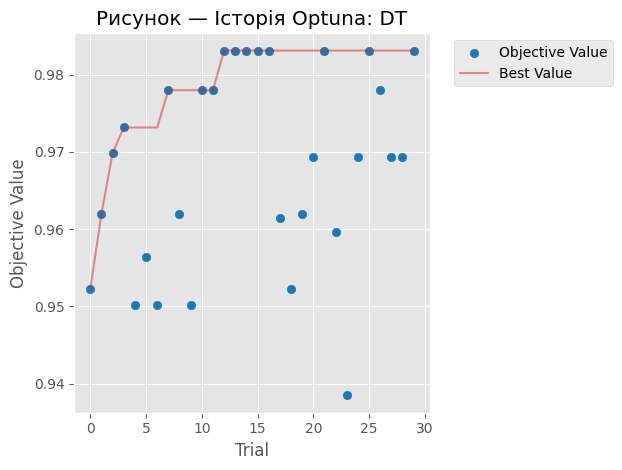

C:\Users\User\AppData\Local\Temp\ipykernel_7012\2683223793.py:6: ExperimentalWarning: optuna.visualization.matplotlib._param_importances.plot_param_importances is experimental (supported from v2.2.0). The interface can change in the future.
  plot_param_importances(study)


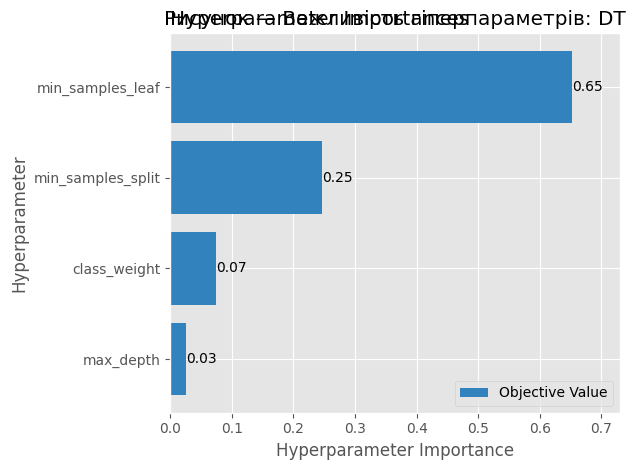

DT Початкова / найкраща macro F1: 0.9523 0.9831


C:\Users\User\AppData\Local\Temp\ipykernel_7012\2683223793.py:4: ExperimentalWarning: optuna.visualization.matplotlib._optimization_history.plot_optimization_history is experimental (supported from v2.2.0). The interface can change in the future.
  plot_optimization_history(study)


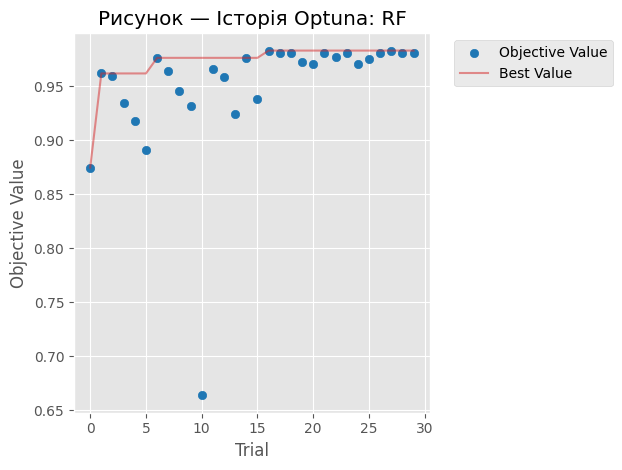

C:\Users\User\AppData\Local\Temp\ipykernel_7012\2683223793.py:6: ExperimentalWarning: optuna.visualization.matplotlib._param_importances.plot_param_importances is experimental (supported from v2.2.0). The interface can change in the future.
  plot_param_importances(study)


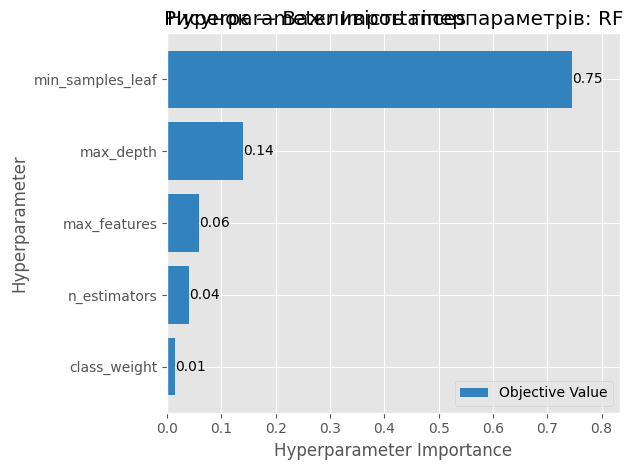

RF Початкова / найкраща macro F1: 0.8748 0.9831


C:\Users\User\AppData\Local\Temp\ipykernel_7012\2683223793.py:4: ExperimentalWarning: optuna.visualization.matplotlib._optimization_history.plot_optimization_history is experimental (supported from v2.2.0). The interface can change in the future.
  plot_optimization_history(study)


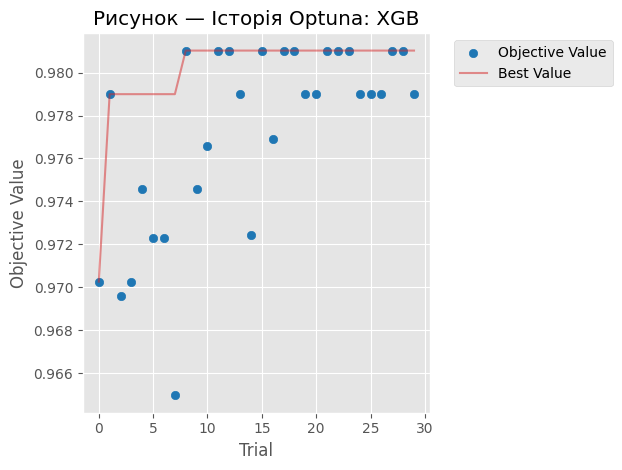

C:\Users\User\AppData\Local\Temp\ipykernel_7012\2683223793.py:6: ExperimentalWarning: optuna.visualization.matplotlib._param_importances.plot_param_importances is experimental (supported from v2.2.0). The interface can change in the future.
  plot_param_importances(study)


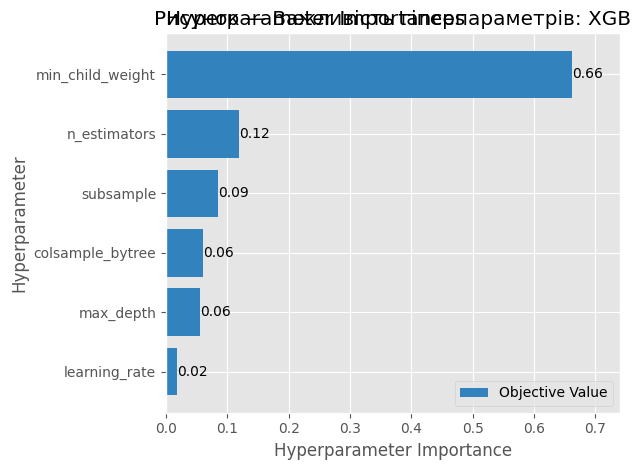

XGB Початкова / найкраща macro F1: 0.9703 0.981


In [9]:
from optuna.visualization.matplotlib import plot_optimization_history,plot_param_importances
for name,study in studies.items():
    try:
        plot_optimization_history(study)
        plt.title(f'Рисунок — Історія Optuna: {name}');plt.tight_layout();plt.show()
        plot_param_importances(study)
        plt.title(f'Рисунок — Важливість гіперпараметрів: {name}');plt.tight_layout();plt.show()
    except Exception as e:
        print(name,'Графік Optuna недоступний:',str(e)[:160])
    values=np.array([t.value for t in study.trials if t.value is not None])
    print(name,'Початкова / найкраща macro F1:',round(values[0],4),round(np.max(values),4))

## 5. Скоригований t-тест Наде–Бенжiо — таблиця 5
Порівнюються парні оцінки на тих самих 15 блоках. Порогове значення α = 0.05. Поправка враховує залежність оцінок між блоками.

In [10]:
def corrected_ttest(a,b,k=5,r=3):
    d=np.asarray(a)-np.asarray(b)
    m=len(d)
    assert m==k*r
    mean=d.mean()
    var=d.var(ddof=1)
    ratio=1/(k-1)  # n_test / n_train для k-fold
    se=np.sqrt((1/m+ratio)*var)
    t_stat=mean/se if se>0 else (0 if abs(mean)<1e-12 else np.sign(mean)*np.inf)
    p=2*student_t.sf(abs(t_stat),df=m-1)
    return mean,t_stat,p
comparisons=[]
for name in ['DT','RF','XGB']:
    comparisons.append((f'{name}: B − A',base_scores[('B',name)]['macro F1'],base_scores[('A',name)]['macro F1']))
ranked=sorted(['DT','RF','XGB'],key=lambda n:base_scores[('B',n)]['macro F1'].mean(),reverse=True)
comparisons.append((f'B: {ranked[0]} − {ranked[1]}',base_scores[('B',ranked[0])]['macro F1'],base_scores[('B',ranked[1])]['macro F1']))
stats_rows=[]
for label,a,b in comparisons:
    d,t,p=corrected_ttest(a,b)
    stats_rows.append({'Порівняння':label,'d̄':round(d,5),'t':round(t,4),'p':round(p,5),
                       'Висновок':'Значуща різниця' if p<0.05 else 'Не виявлено значущої різниці'})
stats_table=pd.DataFrame(stats_rows)
display(Markdown('**Таблиця 5 — Скоригований t-тест**'));display(stats_table)

**Таблиця 5 — Скоригований t-тест**

,Порівняння,d̄,t,p,Висновок
0,DT: B − A,0.08238,4.0530,0.00119,Значуща різниця
1,RF: B − A,0.08851,4.5765,0.00043,Значуща різниця
2,XGB: B − A,0.07182,4.6910,0.00035,Значуща різниця
3,B: RF − XGB,0.00722,0.8605,0.40399,Не виявлено значущої різниці


## 6. Фінальна оцінка на Test — таблиця 6
Тест використовується **один раз** після завершення підбору. Найкраща модель визначається за вкладеною CV, щоб не підбирати її за тестовими метриками.

**Таблиця 6 — Тестові метрики**

,Модель,accuracy,macro F1,balanced accuracy
0,DT,0.9682,0.9367,0.9897
1,RF,0.9809,0.9755,0.9812
2,XGB,0.9745,0.9552,0.9454


Найкраща за nested CV: XGB
              precision    recall  f1-score   support

           2       0.89      0.94      0.91        17
           3       0.98      0.98      0.98       121
           5       1.00      1.00      1.00        12
           U       1.00      0.86      0.92         7

    accuracy                           0.97       157
   macro avg       0.97      0.95      0.96       157
weighted avg       0.98      0.97      0.97       157



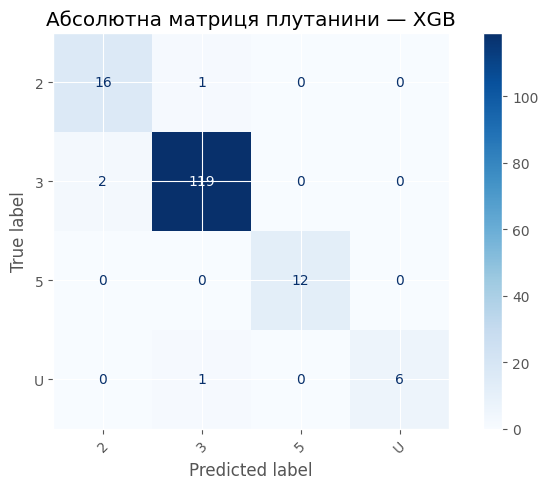

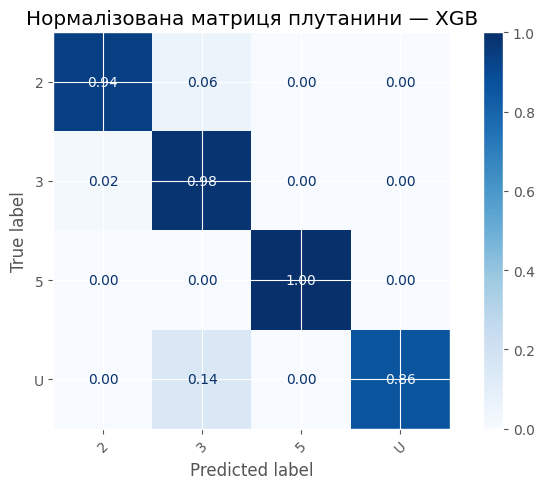

Найчастіші помилки: [(np.int64(2), '3', '2'), (np.int64(1), 'U', '3'), (np.int64(1), '2', '3')]


In [11]:
best_name=max(nested,key=lambda n:nested[n].mean())
predictions={}
test_rows=[]
for name,pipe in final_models.items():
    pred=pipe.predict(X_test)
    predictions[name]=pred
    test_rows.append({'Модель':name,'accuracy':accuracy_score(y_test,pred),
                      'macro F1':f1_score(y_test,pred,average='macro',zero_division=0),
                      'balanced accuracy':balanced_accuracy_score(y_test,pred)})
test_table=pd.DataFrame(test_rows)
display(Markdown('**Таблиця 6 — Тестові метрики**'));display(test_table.round(4))
print('Найкраща за nested CV:',best_name)
print(classification_report(y_test,predictions[best_name],labels=np.arange(len(enc.classes_)),target_names=enc.classes_,zero_division=0))
for normalize,title in [(None,'Абсолютна'),('true','Нормалізована')]:
    fig,ax=plt.subplots(figsize=(7,5))
    ConfusionMatrixDisplay.from_predictions(y_test,predictions[best_name],
        labels=np.arange(len(enc.classes_)),display_labels=enc.classes_,
        normalize=normalize,ax=ax,xticks_rotation=45,cmap='Blues',values_format='.2f' if normalize else 'd')
    ax.set_title(f'{title} матриця плутанини — {best_name}')
    plt.tight_layout();plt.show()
from sklearn.metrics import confusion_matrix
cm=confusion_matrix(y_test,predictions[best_name],labels=np.arange(len(enc.classes_)))
pairs=[(cm[i,j],enc.classes_[i],enc.classes_[j]) for i in range(len(cm)) for j in range(len(cm)) if i!=j and cm[i,j]>0]
print('Найчастіші помилки:',sorted(pairs,reverse=True)[:5] or 'Помилок немає')

## 7. Важливість ознак — MDI і permutation importance
MDI обчислюється для закодованих ознак, permutation — для початкових колонок. Корельовані ознаки можуть ділити важливість між собою.

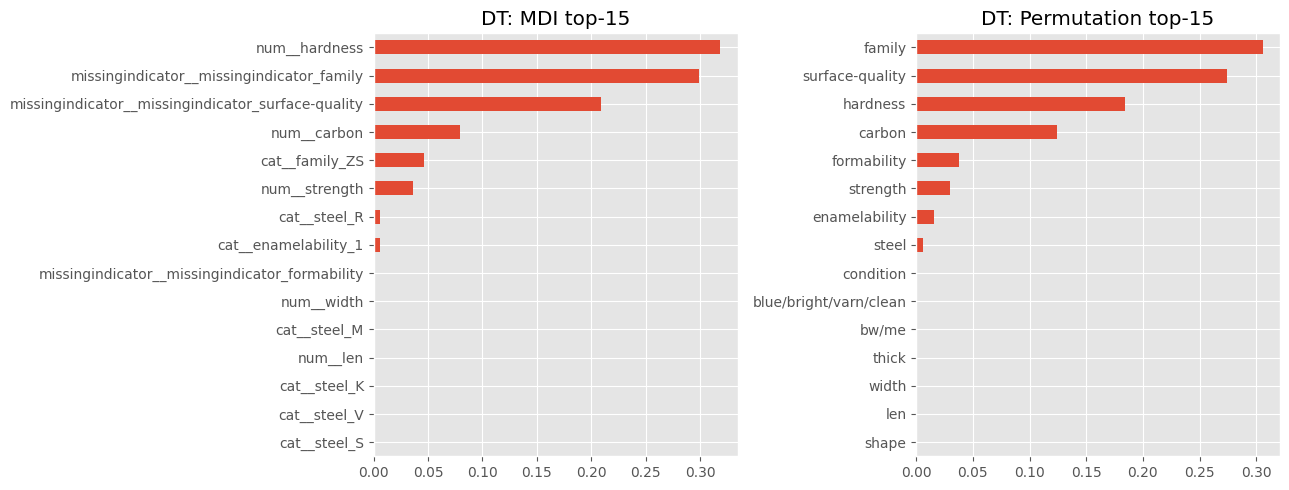

DT Індикатори пропусків у MDI top-15: ['missingindicator__missingindicator_family', 'missingindicator__missingindicator_surface-quality', 'missingindicator__missingindicator_formability']


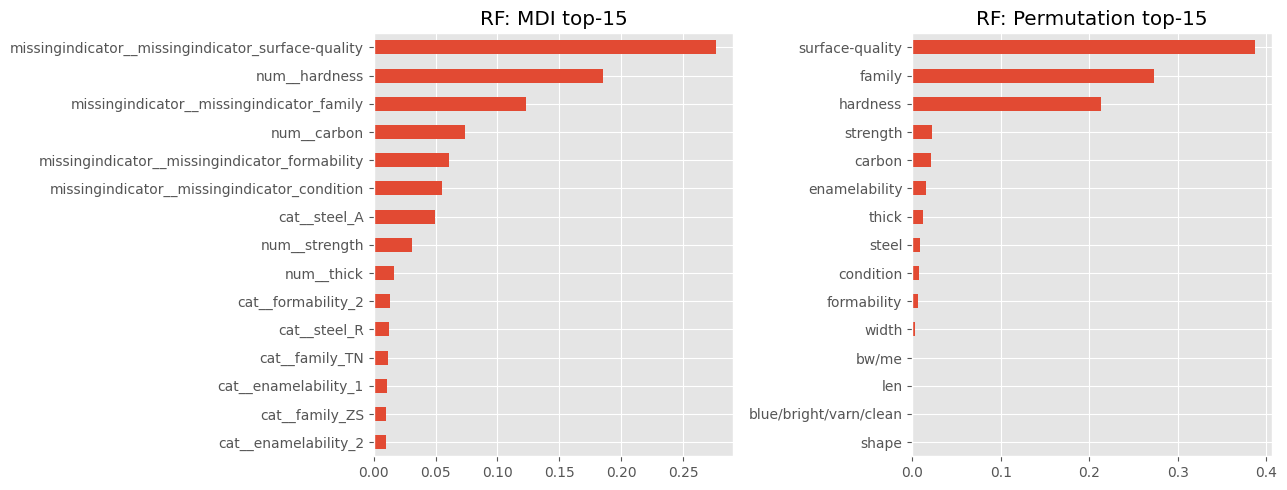

RF Індикатори пропусків у MDI top-15: ['missingindicator__missingindicator_surface-quality', 'missingindicator__missingindicator_family', 'missingindicator__missingindicator_formability', 'missingindicator__missingindicator_condition']


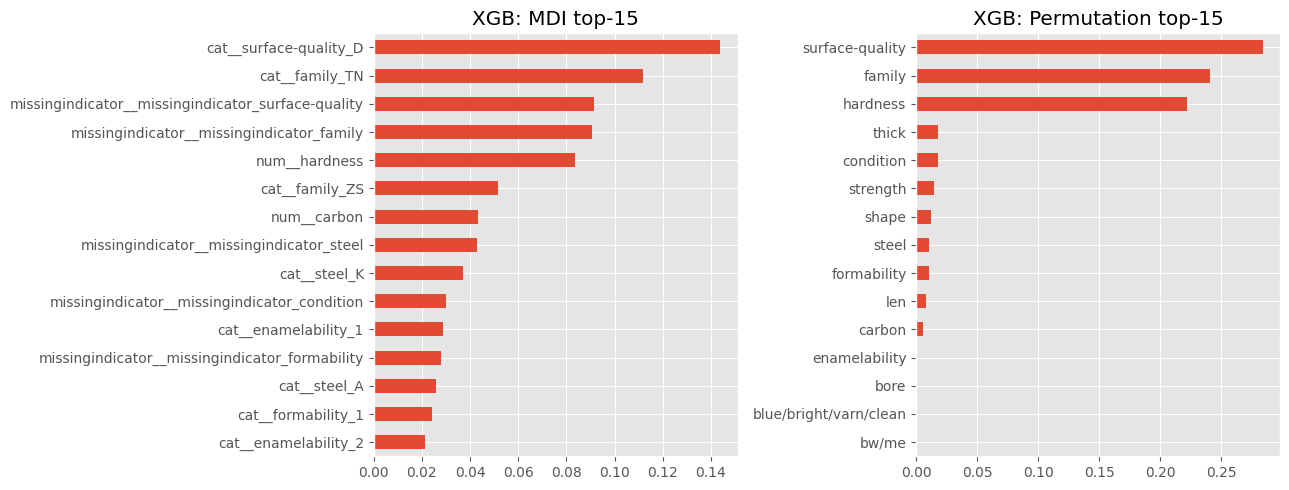

XGB Індикатори пропусків у MDI top-15: ['missingindicator__missingindicator_surface-quality', 'missingindicator__missingindicator_family', 'missingindicator__missingindicator_steel', 'missingindicator__missingindicator_condition', 'missingindicator__missingindicator_formability']


In [12]:
importance_summary={}
for name,pipe in final_models.items():
    prep=pipe.named_steps['prep'];clf=pipe.named_steps['clf']
    feature_names=prep.get_feature_names_out()
    mdi=pd.Series(clf.feature_importances_,index=feature_names).sort_values(ascending=False)
    perm=permutation_importance(pipe,X_test,y_test,n_repeats=10,random_state=SEED,scoring='f1_macro',n_jobs=1)
    pi=pd.Series(perm.importances_mean,index=X_test.columns).sort_values(ascending=False)
    importance_summary[name]=(mdi,pi)
    fig,axes=plt.subplots(1,2,figsize=(13,5))
    mdi.head(15).sort_values().plot.barh(ax=axes[0],title=f'{name}: MDI top-15')
    pi.head(15).sort_values().plot.barh(ax=axes[1],title=f'{name}: Permutation top-15')
    plt.tight_layout();plt.show()
    miss_top=[s for s in mdi.head(15).index if s.startswith('missingindicator__')]
    print(name,'Індикатори пропусків у MDI top-15:',miss_top or 'немає')

## 8. Розбіжності прогнозів — таблиця 7
Шукаємо приклади, на яких моделі не погоджуються. Якщо тестових прикладів менше трьох, додаємо **out-of-fold** прогнози з Train. Не використовуємо прогнози на тих самих даних, на яких модель навчалася.

In [13]:
disagree=np.where((predictions['DT']!=predictions['RF'])|(predictions['DT']!=predictions['XGB']))[0]
disagreements=[('Test',int(i),int(y_test[i]),*[int(predictions[n][i]) for n in ['DT','RF','XGB']]) for i in disagree]
if len(disagreements)<3:
    print('Тестових розбіжностей менше трьох — шукаємо out-of-fold на Train.')
    oof={}
    folds=StratifiedKFold(n_splits=5,shuffle=True,random_state=SEED)
    for name in ['DT','RF','XGB']:
        oof[name]=cross_val_predict(build_pipeline(name,True,studies[name].best_params),X_train,y_train,cv=folds,n_jobs=1)
    oi=np.where((oof['DT']!=oof['RF'])|(oof['DT']!=oof['XGB']))[0]
    disagreements += [('Train OOF',int(i),int(y_train[i]),*[int(oof[n][i]) for n in ['DT','RF','XGB']]) for i in oi[:max(0,3-len(disagreements))]]
dis_table=pd.DataFrame(disagreements,columns=['Джерело','Позиція','Справжній клас','Decision Tree','Random Forest','XGBoost'])
display(Markdown('**Таблиця 7 — Об’єкти розбіжностей**'));display(dis_table.head(15))
if len(dis_table)<3:
    print('Знайдено лише',len(dis_table),'реальних розбіжностей навіть з OOF; вигаданих прикладів не додаємо.')

**Таблиця 7 — Об’єкти розбіжностей**

,Джерело,Позиція,Справжній клас,Decision Tree,Random Forest,XGBoost
0,Test,2,1,3,1,1
1,Test,3,3,3,3,1
2,Test,5,1,3,1,1
3,Test,16,1,1,1,0
4,Test,68,1,0,0,1
5,Test,72,0,0,1,1
6,Test,75,1,3,1,1


### Детальний розбір одного об’єкта
Показуємо всі вихідні значення, пропуски та значення після імпутації. SHAP розраховується окремо для кожної моделі та її прогнозованого класу.

In [14]:
if len(disagreements):
    source,idx,*_=disagreements[0]
    row=(X_test if source=='Test' else X_train).iloc[[idx]]
    print('Джерело:',source,'позиція:',idx)
    raw=row.iloc[0]
    details=pd.DataFrame({'Ознака':raw.index,'Початкове значення':raw.values,'Було пропущено':raw.isna().values})
    for name,pipe in final_models.items():
        prep=pipe.named_steps['prep']
        # Відновлюємо значення імпутації з уже навченої моделі.
        imputed={}
        if num_cols:
            imputed.update(dict(zip(num_cols,prep.named_transformers_['num'].statistics_)))
        if cat_cols:
            imputed.update(dict(zip(cat_cols,prep.named_transformers_['cat'].named_steps['impute'].statistics_)))
        details[f'Заповнення ({name})']=[imputed.get(c,np.nan) if pd.isna(raw[c]) else raw[c] for c in raw.index]
    display(details)
    for name,pipe in final_models.items():
        p=pipe.predict_proba(row)[0]
        print(name,'прогноз:',enc.inverse_transform([np.argmax(p)])[0],
              'ймовірності:',dict(zip(enc.classes_,np.round(p,4))))
else:
    print('Об’єктів розбіжностей немає; SHAP для розбіжності не застосовується.')

Джерело: Test позиція: 2


,Ознака,Початкове значення,Було пропущено,Заповнення (DT),Заповнення (RF),Заповнення (XGB)
0,family,NaN,True,TN,TN,TN
1,steel,A,False,A,A,A
2,carbon,8,False,8,8,8
3,hardness,0,False,0,0,0
4,condition,S,False,S,S,S
5,formability,NaN,True,2,2,2
6,strength,0,False,0,0,0
7,surface-quality,G,False,G,G,G
8,enamelability,NaN,True,2,2,2
9,bw/me,NaN,True,B,B,B


DT прогноз: U ймовірності: {'2': np.float64(0.0), '3': np.float64(0.0584), '5': np.float64(0.0), 'U': np.float64(0.9416)}
RF прогноз: 3 ймовірності: {'2': np.float64(0.0), '3': np.float64(0.8825), '5': np.float64(0.0), 'U': np.float64(0.1175)}
XGB прогноз: 3 ймовірності: {'2': np.float32(0.0008), '3': np.float32(0.998), '5': np.float32(0.0006), 'U': np.float32(0.0006)}



 DT — 5 найбільших SHAP-внесків:


,SHAP
num__carbon,0.488178
missingindicator__missingindicator_surface-quality,0.210539
num__hardness,-0.157547
missingindicator__missingindicator_family,0.128197
num__strength,0.022008


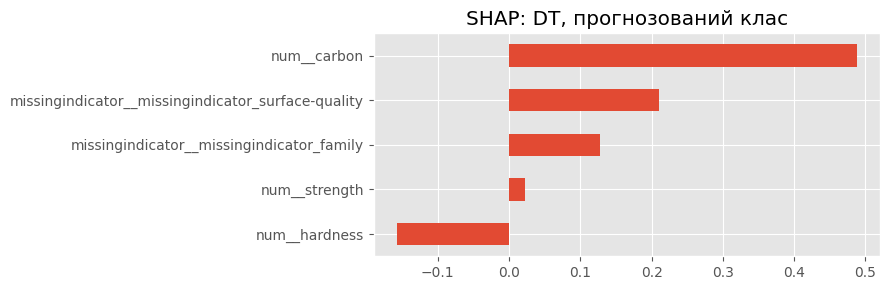


 RF — 5 найбільших SHAP-внесків:


,SHAP
missingindicator__missingindicator_surface-quality,0.101572
num__carbon,-0.082467
num__hardness,0.038616
missingindicator__missingindicator_family,0.020947
cat__steel_A,-0.015423


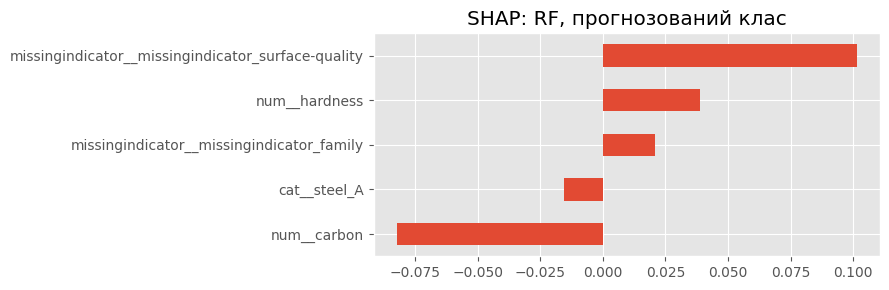


 XGB — 5 найбільших SHAP-внесків:


,SHAP
missingindicator__missingindicator_surface-quality,0.679288
num__thick,0.573510
num__hardness,0.415940
missingindicator__missingindicator_condition,0.271831
missingindicator__missingindicator_family,0.129962


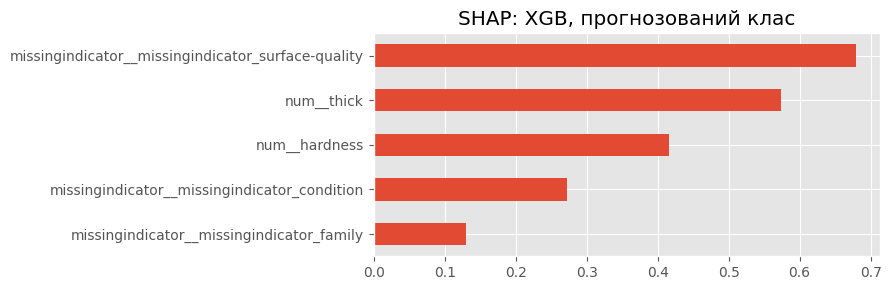

In [15]:
def shap_top5(pipe,row):
    processed=pipe.named_steps['prep'].transform(row)
    features=pipe.named_steps['prep'].get_feature_names_out()
    predicted=int(pipe.predict(row)[0])
    explainer=shap.TreeExplainer(pipe.named_steps['clf'])
    result=explainer(processed)
    vals=np.asarray(result.values)
    if vals.ndim==3:
        contribution=vals[0,:,predicted]
    elif vals.ndim==2:
        contribution=vals[0]
        # Binary TreeExplainer can return one class contribution.
        if len(enc.classes_)==2 and predicted==0:
            contribution=-contribution
    else:
        raise ValueError(f'Неочікувана форма SHAP: {vals.shape}')
    top=pd.Series(contribution,index=features).reindex(
        pd.Series(np.abs(contribution),index=features).nlargest(5).index)
    return top
shap_results={}
if len(disagreements):
    for name,pipe in final_models.items():
        try:
            top=shap_top5(pipe,row)
            shap_results[name]=top
            print('\n',name,'— 5 найбільших SHAP-внесків:')
            display(top.rename('SHAP').to_frame())
            fig,ax=plt.subplots(figsize=(9,3))
            top.sort_values().plot.barh(ax=ax)
            ax.set_title(f'SHAP: {name}, прогнозований клас')
            plt.tight_layout();plt.show()
        except Exception as e:
            print(name,'SHAP-пояснення не вдалося обчислити:',repr(e))

## 9. Підсумкові висновки (автоматично за власними результатами)
Висновок формується з фактичних оцінок, а не з наперед вигаданих чисел.

**Перевірка на дублікати:** усунено повтори об’єктів до поділу Train/Test; після цього перевірено, що між вибірками немає однакових наборів ознак. Фінальні метрики розраховуються тільки після цієї перевірки.

In [16]:
means={n:float(nested[n].mean()) for n in nested}
winner=max(means,key=means.get)
second=sorted(means,key=means.get,reverse=True)[1]
base_b={n:float(base_scores[('B',n)]['macro F1'].mean()) for n in ['DT','RF','XGB']}
gains={n:means[n]-base_b[n] for n in means}
gain_winner=max(gains,key=gains.get)
p_row=stats_table[stats_table['Порівняння']==f'B: {ranked[0]} − {ranked[1]}']
sig=(float(p_row.iloc[0]['p'])<0.05) if len(p_row) else False
best_test=float(test_table.loc[test_table['Модель']==winner,'macro F1'].iloc[0])
changed={n:base_scores[('B',n)]['macro F1'].mean()-base_scores[('A',n)]['macro F1'].mean() for n in means}
hard=sorted(pairs,reverse=True)[:1]
text=[
f'1. У роботі використано Annealing з {len(X)} об’єктами після обґрунтованого виключення рідкісних класів та {X.shape[1]} ознаками.',
f'2. Найвищий середній macro F1 за вкладеною CV отримала модель {winner}: {means[winner]:.4f} (SD {nested[winner].std(ddof=1):.4f}).',
f'3. Наступна за якістю модель — {second}, macro F1 = {means[second]:.4f}; для базових моделей B статистичне порівняння двох лідерів {"виявило" if sig else "не виявило"} значущу різницю.',
f'4. Індикатори пропусків змінили macro F1 так: '+', '.join(f'{n}: {v:+.4f}' for n,v in changed.items())+'.',
f'5. Аналіз χ² показав зв’язок пропусків із класом у {int(chi_df["Зв’язок із класом (p<0.05)"].sum()) if len(chi_df) else 0} із {len(chi_df)} досліджених ознак; це не доводить MAR чи MNAR.',
f'6. Для {winner} різниця між best_value Optuna та вкладеною CV становила {studies[winner].best_value-means[winner]:+.4f}, що показує можливе оптимістичне зміщення.',
f'7. Найбільшу зміну оцінки відносно базового варіанту B показала модель {gain_winner}: {gains[gain_winner]:+.4f}; це порівняння різних CV-процедур, тому не є чистою оцінкою ефекту налаштування.',
f'8. На незалежному Test модель {winner} отримала macro F1 = {best_test:.4f}.',
f'9. Найпомітніша плутанина класів: {hard[0][1]} → {hard[0][2]} ({hard[0][0]} випадків).' if hard else '9. Для найкращої моделі на Test міжкласових помилок не виявлено.',
f'10. Знайдено {len(disagreements)} об’єктів розбіжностей між прогнозами моделей, з яких {sum(x[0]=="Test" for x in disagreements)} належать до Test.',
'11. MDI оцінює важливість після кодування, а permutation importance — на початкових ознаках; їхні результати не обов’язково однакові.',
f'12. Для практичного застосування доцільно розглядати {winner}, але також враховувати стабільність, швидкість та зрозумілість пояснень.'
]
display(Markdown('\n\n'.join(text)))

1. У роботі використано Annealing з 785 об’єктами після обґрунтованого виключення рідкісних класів та 18 ознаками.

2. Найвищий середній macro F1 за вкладеною CV отримала модель XGB: 0.9782 (SD 0.0135).

3. Наступна за якістю модель — RF, macro F1 = 0.9774; для базових моделей B статистичне порівняння двох лідерів не виявило значущу різницю.

4. Індикатори пропусків змінили macro F1 так: DT: +0.0824, RF: +0.0885, XGB: +0.0718.

5. Аналіз χ² показав зв’язок пропусків із класом у 4 із 5 досліджених ознак; це не доводить MAR чи MNAR.

6. Для XGB різниця між best_value Optuna та вкладеною CV становила +0.0028, що показує можливе оптимістичне зміщення.

7. Найбільшу зміну оцінки відносно базового варіанту B показала модель XGB: -0.0022; це порівняння різних CV-процедур, тому не є чистою оцінкою ефекту налаштування.

8. На незалежному Test модель XGB отримала macro F1 = 0.9552.

9. Найпомітніша плутанина класів: 3 → 2 (2 випадків).

10. Знайдено 7 об’єктів розбіжностей між прогнозами моделей, з яких 7 належать до Test.

11. MDI оцінює важливість після кодування, а permutation importance — на початкових ознаках; їхні результати не обов’язково однакові.

12. Для практичного застосування доцільно розглядати XGB, але також враховувати стабільність, швидкість та зрозумілість пояснень.

## 10. Контрольні питання — короткі відповіді
1. **Дерево і ліс:** одне дерево має більшу нестабільність, а ліс усереднює різні дерева та зменшує розкид помилок; декореляція робить дерева менш схожими.
2. **Беггінг і бустинг:** беггінг навчає дерева незалежно й об'єднує їх, бустинг додає дерева послідовно для виправлення попередніх помилок. За надмірного налаштування бустинг може перенавчитися.
3. **Macro F1 / balanced accuracy:** однаково враховують рідкісні класи; accuracy може приховувати їхні помилки. Weighted F1 надає більше ваги чисельним класам.
4. **MCAR / MAR / MNAR:** пропуск випадковий; залежить від відомих ознак; залежить від невідомого значення. Індикатори корисні, якщо факт пропуску інформативний. MAR та MNAR не завжди розрізнити з даних.
5. **Data Leakage:** виникає, якщо заповнення пропусків чи підбір параметрів «бачить» тестові/валідаційні дані. Запобігає Pipeline всередині CV.
6. **Optuna best_value / nested CV:** best_value обирається як максимум багатьох спроб, тому часто завищене. Зовнішня CV оцінює всю процедуру підбору, а не одну фіксовану модель.
7. **t-тест:** оцінки CV залежні, бо навчальні частини перекриваються. Поправка Наде–Бенжіо збільшує оцінку дисперсії.
8. **MDI / permutation:** MDI вимірює зменшення неоднорідності, permutation — падіння якості після перемішування ознаки. Кореляції можуть спотворювати обидва.
9. **SHAP:** показує внесок ознак в окремий прогноз; сума внесків із базовим значенням відновлює вихід моделі у відповідному просторі.
10. **XGBoost і NaN:** під час пошуку розбиття вивчає, у яку гілку спрямовувати пропущені значення.
11. **Optuna:** TPE спрямовує пошук на перспективні параметри, pruning може зупиняти слабкі спроби раніше; GridSearch перебирає сітку, RandomizedSearch — випадкові комбінації.